In [33]:
# Import the library to mount Google Drive
from google.colab import drive

import h5py
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

In [34]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [35]:
file_name = "RRUFF_norm.hdf5"
file_path = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name}"
data_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

In [36]:
def print_hdf5_structure(name, obj):
    print(name)

with h5py.File(file_path, "r") as f:
    f.visititems(print_hdf5_structure)

Streaming output truncated to the last 5000 lines.
Grossular__R050081-1__4184/2theta
Grossular__R050081-1__4184/intensity
Grossular__R050312-1__5656
Grossular__R050312-1__5656/2theta
Grossular__R050312-1__5656/intensity
Grossular__R060278-1__6777
Grossular__R060278-1__6777/2theta
Grossular__R060278-1__6777/intensity
Grossular__R060442-1__3272
Grossular__R060442-1__3272/2theta
Grossular__R060442-1__3272/intensity
Grossular__R060443-1__3137
Grossular__R060443-1__3137/2theta
Grossular__R060443-1__3137/intensity
Grossular__R060444-1__3275
Grossular__R060444-1__3275/2theta
Grossular__R060444-1__3275/intensity
Grossular__R060446-1__5603
Grossular__R060446-1__5603/2theta
Grossular__R060446-1__5603/intensity
Grossular__R060452-1__3080
Grossular__R060452-1__3080/2theta
Grossular__R060452-1__3080/intensity
Grossular__R060453-1__3086
Grossular__R060453-1__3086/2theta
Grossular__R060453-1__3086/intensity
Grossular__R060499-1__4891
Grossular__R060499-1__4891/2theta
Grossular__R060499-1__4891/intens

In [37]:
# List of dataset paths you want to inspect
datasets = [
    "Grossular__R060278-1__6777/2theta",
    "Grossular__R060278-1__6777/intensity",
    "Grossular__R060442-1__3272",
    "Grossular__R060442-1__3272/2theta",
    "Grossular__R060442-1__3272/intensity",
]

# Number of elements to preview from each dataset
n_preview = 10

with h5py.File(file_path, "r") as f:
    for dset_path in datasets:
        if dset_path not in f:
            print(f"\n⚠️ Not found: {dset_path}")
            continue

        obj = f[dset_path]

        if isinstance(obj, h5py.Group):
            print(f"\n📁 Group: {dset_path}")
            print(f"  Contains: {list(obj.keys())}")
        elif isinstance(obj, h5py.Dataset):
            data = obj[()]
            print(f"\n📂 Dataset: {dset_path}")
            print(f"  Shape: {data.shape}")
            print(f"  Dtype: {data.dtype}")
            print(f"  First {n_preview} values:\n  {data[:n_preview]}")
        else:
            print(f"\n❓ Unknown object type at: {dset_path}")


📂 Dataset: Grossular__R060278-1__6777/2theta
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [5.   5.01 5.02 5.03 5.04 5.05 5.06 5.07 5.08 5.09]

📂 Dataset: Grossular__R060278-1__6777/intensity
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [ 68.10035842  96.77419355  46.59498208 107.52688172  93.18996416
 107.52688172 103.94265233 100.35842294  93.18996416  89.60573477]

📁 Group: Grossular__R060442-1__3272
  Contains: ['2theta', 'intensity']

📂 Dataset: Grossular__R060442-1__3272/2theta
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [5.   5.01 5.02 5.03 5.04 5.05 5.06 5.07 5.08 5.09]

📂 Dataset: Grossular__R060442-1__3272/intensity
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [47.49679076 44.92939666 34.65982028 32.09242619 43.64569961 39.79460847
 43.64569961 37.22721438 52.63157895 42.36200257]


In [38]:
import h5py
import numpy as np
import pandas as pd

#file_path = "your_file.hdf5"  # <-- update this

records = []
dataset_count = 0
group_count = 0

def summarize_dataset(name, obj):
    """Collect dataset statistics into a list of dicts for DataFrame summary."""
    global dataset_count, group_count

    if isinstance(obj, h5py.Group):
        group_count += 1
        return

    if isinstance(obj, h5py.Dataset):
        dataset_count += 1
        data = obj[()]
        record = {
            "path": name,
            "shape": data.shape,
            "dtype": str(data.dtype),
            "size": data.size,
        }

        # Handle empty datasets
        if data.size == 0:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "empty",
            })
        elif np.issubdtype(data.dtype, np.number):
            nan_mask = np.isnan(data)
            nan_count = nan_mask.sum() if np.any(nan_mask) else 0
            record.update({
                "min": np.nanmin(data),
                "max": np.nanmax(data),
                "mean": np.nanmean(data),
                "std": np.nanstd(data),
                "nan_count": nan_count,
                "status": "ok" if nan_count == 0 else "contains_nans",
            })
        else:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "non-numeric",
            })

        records.append(record)

# --- Traverse file ---
with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring file: {file_path}")
    f.visititems(summarize_dataset)

# --- Load into DataFrame ---
df = pd.DataFrame(records)

print("\n" + "="*80)
print(f"📊 Total groups (samples): {group_count}")
print(f"📊 Total datasets: {dataset_count}")
print("="*80)

# --- Display summary ---
print("\n🔍 DataFrame Summary:")
print(df.head())

# --- Example aggregate statistics ---
print("\n📈 Global Stats Summary:")
print(df[["min", "max", "mean", "std", "nan_count"]].describe())

# Optionally save to CSV for later analysis
# df.to_csv("hdf5_summary.csv", index=False)


📘 Exploring file: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm.hdf5

📊 Total groups (samples): 2795
📊 Total datasets: 5590

🔍 DataFrame Summary:
                                    path    shape    dtype  size  min     max  \
0             Abhurite__R060227-9/2theta  (8501,)  float64  8501  5.0    90.0   
1          Abhurite__R060227-9/intensity  (8501,)  float64  8501  0.0  1000.0   
2     Acanthite__R070578-9__11911/2theta  (8501,)  float64  8501  5.0    90.0   
3  Acanthite__R070578-9__11911/intensity  (8501,)  float64  8501  0.0  1000.0   
4      Acanthite__R080016-1__9704/2theta  (8501,)  float64  8501  5.0    90.0   

        mean        std  nan_count status  
0  47.500000  24.540273          0     ok  
1  21.450545  63.997562          0     ok  
2  47.500000  24.540273          0     ok  
3  28.028205  86.199706          0     ok  
4  47.500000  24.540273          0     ok  

📈 Global Stats Summary:
               min          max         

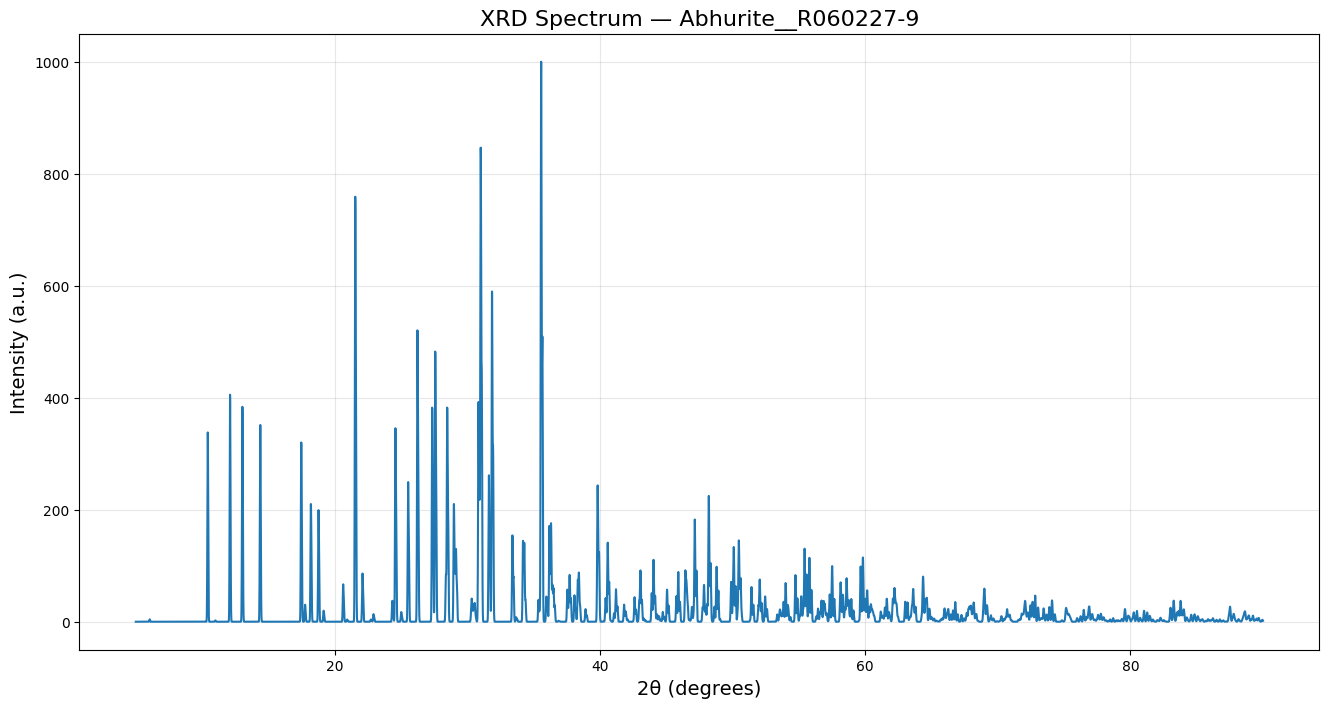

In [39]:
import h5py
import numpy as np
import matplotlib.pyplot as plt


with h5py.File(file_path, "r") as f:
    base = "Abhurite__R060227-9"
    if f"{base}/2theta" in f and f"{base}/intensity" in f:
        two_theta = f[f"{base}/2theta"][()]
        intensity = f[f"{base}/intensity"][()]

        plt.figure(figsize=(16, 8))
        plt.plot(two_theta, intensity, color='tab:blue', linewidth=1.5)
        plt.title(f"XRD Spectrum — {base}", fontsize=16)
        plt.xlabel("2θ (degrees)", fontsize=14)
        plt.ylabel("Intensity (a.u.)", fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print(f"❌ Missing 2θ or intensity dataset under {base}")


In [40]:
import h5py
import numpy as np
import pandas as pd

#file_path = "your_file.hdf5"  # change this

intensity_stats = []

def summarize_intensity(name, obj):
    # Only include datasets ending in "intensity"
    if isinstance(obj, h5py.Dataset) and name.endswith("/intensity"):
        data = obj[()]
        if data.size == 0:
            return
        stats = {
            "path": name,
            "size": data.size,
            "min": np.nanmin(data),
            "max": np.nanmax(data),
            "mean": np.nanmean(data),
            "std": np.nanstd(data),
            "nan_count": np.isnan(data).sum(),
        }
        intensity_stats.append(stats)

# Traverse recursively
with h5py.File(file_path, "r") as f:
    f.visititems(summarize_intensity)

# Convert to DataFrame
df = pd.DataFrame(intensity_stats)

# --- Print summary ---
print(f"📈 Total intensity datasets found: {len(df)}\n")
print("🧩 Per-dataset statistics (first few):")
print(df.head())

print("\n📊 Global summary across all intensity datasets:")
print(df.describe())

# Optional: check for NaNs across all spectra
total_nans = df["nan_count"].sum()
print(f"\n🔍 Total NaN values across all intensity datasets: {total_nans}")


📈 Total intensity datasets found: 2795

🧩 Per-dataset statistics (first few):
                                    path  size        min     max        mean  \
0          Abhurite__R060227-9/intensity  8501   0.000000  1000.0   21.450545   
1  Acanthite__R070578-9__11911/intensity  8501   0.000000  1000.0   28.028205   
2   Acanthite__R080016-1__9704/intensity  8501  18.656716  1000.0  188.668761   
3  Actinolite__R040063-1__3301/intensity  8500   8.830022  1000.0   27.032204   
4  Actinolite__R040064-1__3305/intensity  8500  12.455516  1000.0   37.018317   

          std  nan_count  
0   63.997562          0  
1   86.199706          0  
2  169.231794          0  
3   37.501408          0  
4   34.701992          0  

📊 Global summary across all intensity datasets:
              size          min     max         mean          std  nan_count
count  2795.000000  2795.000000  2795.0  2795.000000  2795.000000     2795.0
mean   8459.583542    12.233602  1000.0    40.858486    49.447003     

In [41]:
import h5py

def list_attributes(name, obj):
    # If this object has attributes, print them
    if len(obj.attrs) > 0:
        print(f"\n📁 Path: {name}")
        for key, value in obj.attrs.items():
            print(f"  ├─ {key}: {value}")

with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring attributes in: {file_path}")
    print("=" * 80)
    f.visititems(list_attributes)
    print("\n✅ Attribute listing complete.")


Streaming output truncated to the last 5000 lines.

📁 Path: Grossular__R050312-1__5656
  ├─ eg: 93

📁 Path: Grossular__R060278-1__6777
  ├─ eg: 93

📁 Path: Grossular__R060442-1__3272
  ├─ eg: 93

📁 Path: Grossular__R060443-1__3137
  ├─ eg: 93

📁 Path: Grossular__R060444-1__3275
  ├─ eg: 93

📁 Path: Grossular__R060446-1__5603
  ├─ eg: 93

📁 Path: Grossular__R060452-1__3080
  ├─ eg: 93

📁 Path: Grossular__R060453-1__3086
  ├─ eg: 93

📁 Path: Grossular__R060499-1__4891
  ├─ eg: 93

📁 Path: Grossular__R070551-1__8658
  ├─ eg: 93

📁 Path: Grossular__R100146-9__11222
  ├─ eg: 93

📁 Path: Grossular__R100160-9__11238
  ├─ eg: 93

📁 Path: Grossular__R100161-9__11240
  ├─ eg: 93

📁 Path: Groutite__R070583-9__9494
  ├─ eg: 17

📁 Path: Groutite__R080004-9__9192
  ├─ eg: 17

📁 Path: Grunerite__R040150-1__3838
  ├─ eg: 5

📁 Path: Grunerite__R060062-1__6525
  ├─ eg: 5

📁 Path: Grunerite__R070186-9__8357
  ├─ eg: 5

📁 Path: Grunerite__R070204-1__8224
  ├─ eg: 5

📁 Path: Grunerite__R070267-9__8367
  ├─

In [42]:
import h5py
import numpy as np

# open the source file
with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    # iterate through all top-level groups (e.g., Hastingsite__R070124-1__8096)
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        # ensure intensity dataset exists
        if "intensity" not in group:
            print(f"Skipping {key}, no intensity dataset")
            continue

        # load full intensity (length ~8501)
        intensity = group["intensity"][:]

        # compute uniform sampling indices
        n_points = 1000
        idx = np.linspace(0, len(intensity) - 1, n_points, dtype=int)
        sampled = intensity[idx]

        X_list.append(sampled)

        # extract attribute value (e.g., group.attrs["eg"])
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            # fallback: if there’s only one attribute, use it
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                print(f"No valid attribute found for {key}")
                continue

        y_list.append(y_value)

    # convert to numpy arrays
    X_test = np.array(X_list)
    y_test = np.array(y_list)

# save into a new compact file
file_name_sampled = "RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5"
file_path_sampled = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_sampled}"

with h5py.File(file_path_sampled, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved {len(X_test)} samples to {file_path_sampled}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


✅ Saved 2795 samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5
Shape: X_test=(2795, 1000), y_test=(2795,)


Reduced Range

In [43]:
import h5py
import numpy as np

# Path to your original HDF5 file
#h5_path = "your_file.hdf5"

# Full measurement range (from metadata or known acquisition setup)
theta_min, theta_max = 5.0, 90.0
target_min, target_max = 10.0, 80.0

# open the file and process
with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        if "intensity" not in group:
            print(f"Skipping {key}, no intensity dataset")
            continue

        intensity = group["intensity"][:]
        n_points = len(intensity)

        # create synthetic 2θ grid across [5°, 90°]
        two_theta = np.linspace(theta_min, theta_max, n_points)

        # select only the range [10°, 80°]
        mask = (two_theta >= target_min) & (two_theta <= target_max)
        reduced_intensity = intensity[mask]
        reduced_theta = two_theta[mask]

        # (optional) resample to 1000 uniform points across 10–80°
        n_target = 700
        new_theta = np.linspace(target_min, target_max, n_target)
        sampled_intensity = np.interp(new_theta, reduced_theta, reduced_intensity)

        X_list.append(sampled_intensity)

        # get label (attribute)
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                print(f"No valid attribute for {key}")
                continue

        y_list.append(y_value)

    X_test = np.array(X_list)
    y_test = np.array(y_list)

# save into a new compact reduced range file
file_name_reduced = "RRUFF_norm_reduced_range_10_80_deg_700_intensity.hdf5"
file_path_reduced = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_reduced}"

with h5py.File(file_path_reduced, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved reduced-range samples to {file_path_reduced}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


✅ Saved reduced-range samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_reduced_range_10_80_deg_700_intensity.hdf5
Shape: X_test=(2795, 700), y_test=(2795,)


X_test shape: (2795, 700)
y_test shape: (2795,)
Unique labels: [ 1  2  3  4  5  6  7  9 10 11 12 14 15 16 17 18 19 21 22 23 24 26 28 29
 30 31 32 33 34 35 37 38 39 40 41 42 44 45 46 47 48 49 51 52 53 54 55 58
 60 62 63 65 68 69 70 71 72 73 74 75 76 77 80 81 82 85 86 87 89 90 91 92
 93 94 95 97 98 99]

📊 Intensity Summary Statistics:
        mean        std  min         max
0  34.852527  86.769922  0.0  968.610000
1  33.839784  84.789070  0.0  999.639914
2  36.355399  95.093634  0.0  999.424320
3  34.603533  87.986898  0.0  996.282833
4  37.028831  93.036411  0.0  974.151709

🧾 Label Distribution:
    count
1       5
2      89
3      41
4     314
5     242
..    ...
94     52
95      2
97     70
98      1
99    279

[78 rows x 1 columns]


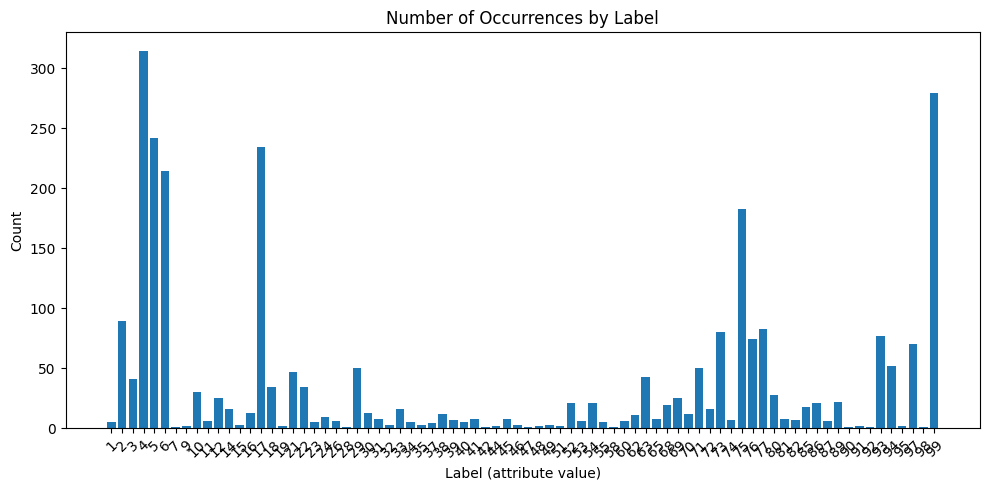

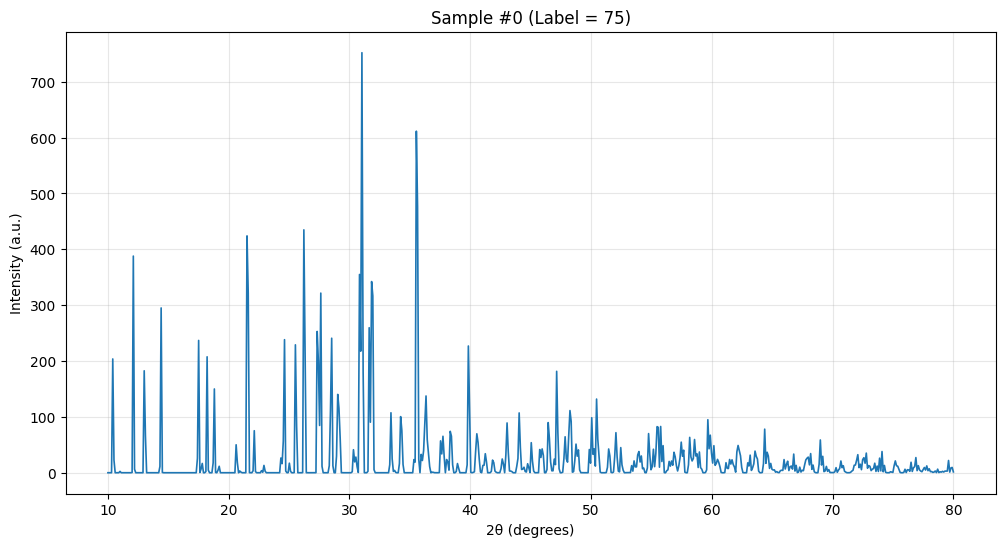

In [44]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Path to your reduced dataset
#file_path_reduced = "intensity_test_data_10_80deg.hdf5"

with h5py.File(file_path_reduced, "r") as f:
    X_test = f["X_test"][:]
    y_test = f["y_test"][:]

# -----------------------------
# 🧩 Basic Info
# -----------------------------
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"Unique labels: {np.unique(y_test)}")

# Summary statistics
df_stats = pd.DataFrame(X_test)
summary = df_stats.describe().T[["mean", "std", "min", "max"]]
print("\n📊 Intensity Summary Statistics:")
print(summary.head())

# -----------------------------
# 🧮 Label Distribution
# -----------------------------
label_counts = Counter(y_test)
label_df = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"])
label_df = label_df.sort_index()

print("\n🧾 Label Distribution:")
print(label_df)

plt.figure(figsize=(10, 5))
plt.bar(label_df.index.astype(str), label_df["count"])
plt.xlabel("Label (attribute value)")
plt.ylabel("Count")
plt.title("Number of Occurrences by Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -----------------------------
# 📈 Plot a sample intensity spectrum
# -----------------------------
sample_idx = 0  # change this to view a different sample
n_points = X_test.shape[1]
two_theta = np.linspace(10, 80, n_points)

plt.figure(figsize=(12, 6))
plt.plot(two_theta, X_test[sample_idx], lw=1.2)
plt.title(f"Sample #{sample_idx} (Label = {y_test[sample_idx]})")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True, alpha=0.3)
plt.show()


In [49]:
import h5py
import numpy as np

def ensure_splits_exist(h5_path):
    with h5py.File(h5_path, "a") as f:
        # Check if test split exists to copy metadata
        if "X_test" not in f:
            raise ValueError("No 'X_test' found — cannot infer shape for empty splits.")

        x_shape = f["X_test"].shape[1]  # number of intensity points
        dtype = f["X_test"].dtype

        # Define shape for empty splits (0 samples, same feature width)
        empty_shape = (0, x_shape)
        y_dtype = f["y_test"].dtype

        # Create X_train and y_train if missing
        if "X_train" not in f:
            f.create_dataset("X_train", shape=empty_shape, dtype=dtype)
            print("✅ Created empty X_train")

        if "y_train" not in f:
            f.create_dataset("y_train", shape=(0,), dtype=y_dtype)
            print("✅ Created empty y_train")

        # Create X_val and y_val if missing
        if "X_val" not in f:
            f.create_dataset("X_val", shape=empty_shape, dtype=dtype)
            print("✅ Created empty X_val")

        if "y_val" not in f:
            f.create_dataset("y_val", shape=(0,), dtype=y_dtype)
            print("✅ Created empty y_val")

    print(f"✅ File '{h5_path}' is now compatible with all splits.")


In [50]:
ensure_splits_exist(file_path_reduced)


✅ Created empty X_train
✅ Created empty y_train
✅ Created empty X_val
✅ Created empty y_val
✅ File '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_reduced_range_10_80_deg_700_intensity.hdf5' is now compatible with all splits.


In [51]:
ensure_splits_exist(file_path_sampled)

✅ Created empty X_train
✅ Created empty y_train
✅ Created empty X_val
✅ Created empty y_val
✅ File '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5' is now compatible with all splits.
